Event Related PAC object defined


Participant: s1_pac_sub01
Condition: FTT_plan | ROI: M1
Data shape: (66, 501)
Sampling frequency: 500.0 Hz


    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python


Observed ERPAC shape: (45, 501)


    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
 

Surrogate array shape: (100, 45, 501)

--- SURROGATE RESULTS ---
Observed ERPAC:      0.149922
Surrogate mean:      0.156090
Surrogate SD:        0.009693
Surrogate z-score:   -0.636
Empirical p (upper): 0.7327


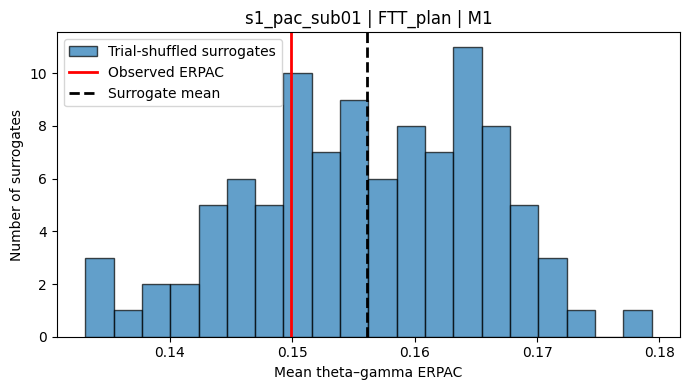

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tensorpac import EventRelatedPac

# ============================================================
# SETTINGS
# ============================================================

SUBJECT = "s1_pac_sub01"
GROUP = "Y"
ROI = "M1"
CONDITION = "FTT_plan"

N_SURROGATES = 100
RANDOM_SEED = 42

PCA_ROOT = Path(r"F:\# study 2\eeg_data\erpac\PCA")

file_path = (
    PCA_ROOT / "stcs_ave_vtx" / GROUP / SUBJECT
    / f"{CONDITION}_{ROI}_pca_roi_tc.npz"
)

# ============================================================
# LOAD ROI TIME SERIES
# ============================================================

with np.load(file_path, allow_pickle=True) as npz:
    x = np.asarray(npz["data"], dtype=float)[:, 0, :]
    times = np.asarray(npz["times"], dtype=float)

sf = 1.0 / np.median(np.diff(times))

print(f"Participant: {SUBJECT}")
print(f"Condition: {CONDITION} | ROI: {ROI}")
print(f"Data shape: {x.shape}")
print(f"Sampling frequency: {sf:.1f} Hz")

# ============================================================
# COMPUTE OBSERVED ERPAC
# ============================================================

p = EventRelatedPac(
    f_pha=[4, 8],
    f_amp=(30, 80, 5, 1),
)

# Filter only once
pha = p.filter(sf, x, ftype="phase", n_jobs=1)
amp = p.filter(sf, x, ftype="amplitude", n_jobs=1)

observed = np.asarray(
    p.fit(pha, amp, method="circular", n_jobs=1)
).squeeze()

print(f"Observed ERPAC shape: {observed.shape}")

# ============================================================
# GENERATE TRIAL-SHUFFLED SURROGATES
# ============================================================

rng = np.random.default_rng(RANDOM_SEED)
surrogates = []

for i in range(N_SURROGATES):

    # One trial permutation for the entire time series
    perm = rng.permutation(x.shape[0])

    surrogate = np.asarray(
        p.fit(
            pha,
            amp[:, perm, :],
            method="circular",
            n_jobs=1,
        )
    ).squeeze()

    surrogates.append(surrogate)

surrogates = np.stack(surrogates, axis=0)

print(f"Surrogate array shape: {surrogates.shape}")

# ============================================================
# WINDOW-LEVEL COMPARISON
# ============================================================

# FTT planning: 0–0.5 s
mask = (times >= 0.0) & (times < 0.5)

observed_mean = observed[:, mask].mean()

# Average each surrogate over gamma frequencies and time
null_values = surrogates[:, :, mask].mean(axis=(1, 2))

null_mean = null_values.mean()
null_sd = null_values.std(ddof=1)

z_erpac = (observed_mean - null_mean) / null_sd

p_upper = (
    1 + np.sum(null_values >= observed_mean)
) / (N_SURROGATES + 1)

print("\n--- SURROGATE RESULTS ---")
print(f"Observed ERPAC:      {observed_mean:.6f}")
print(f"Surrogate mean:      {null_mean:.6f}")
print(f"Surrogate SD:        {null_sd:.6f}")
print(f"Surrogate z-score:   {z_erpac:.3f}")
print(f"Empirical p (upper): {p_upper:.4f}")

# ============================================================
# VISUALISE SURROGATE DISTRIBUTION
# ============================================================

fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    null_values,
    bins=20,
    alpha=0.7,
    edgecolor="black",
    label="Trial-shuffled surrogates",
)

ax.axvline(
    observed_mean,
    linewidth=2,
    color="red",
    label="Observed ERPAC",
)

ax.axvline(
    null_mean,
    linewidth=2,
    linestyle="--",
    color="black",
    label="Surrogate mean",
)

ax.set(
    xlabel="Mean theta–gamma ERPAC",
    ylabel="Number of surrogates",
    title=f"{SUBJECT} | {CONDITION} | {ROI}",
)

ax.legend()
plt.tight_layout()
plt.show()


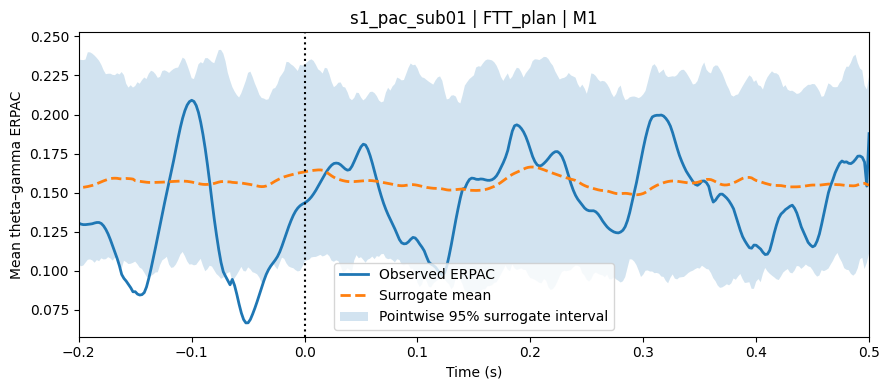

In [2]:
# ============================================================
# TIME-RESOLVED OBSERVED VS SURROGATE ERPAC
# ============================================================

# Average over gamma frequencies, retaining time
observed_tc = observed.mean(axis=0)

# Surrogate time courses:
# (surrogates, gamma frequencies, times)
#                ↓
# (surrogates, times)
surrogate_tc = surrogates.mean(axis=1)

surrogate_mean_tc = surrogate_tc.mean(axis=0)

# Pointwise 95% surrogate interval
surrogate_lower = np.percentile(
    surrogate_tc, 2.5, axis=0
)
surrogate_upper = np.percentile(
    surrogate_tc, 97.5, axis=0
)

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    times, observed_tc,
    label="Observed ERPAC",
    linewidth=2,
)

ax.plot(
    times, surrogate_mean_tc,
    label="Surrogate mean",
    linestyle="--",
    linewidth=2,
)

ax.fill_between(
    times,
    surrogate_lower,
    surrogate_upper,
    alpha=0.2,
    label="Pointwise 95% surrogate interval",
)

ax.axvline(0, linestyle=":", color="black")

ax.set_xlim(-0.2, 0.5)
ax.set(
    xlabel="Time (s)",
    ylabel="Mean theta–gamma ERPAC",
    title=f"{SUBJECT} | {CONDITION} | {ROI}",
)

ax.legend()
plt.tight_layout()
plt.show()


Synthetic ERPAC validation

Event Related PAC object defined
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Com


--- Negative control: independent phase/amplitude ---
Observed ERPAC:  0.154804
Surrogate mean:  0.157794
Surrogate SD:    0.015949
Surrogate z:     -0.187
Empirical p:     0.5572


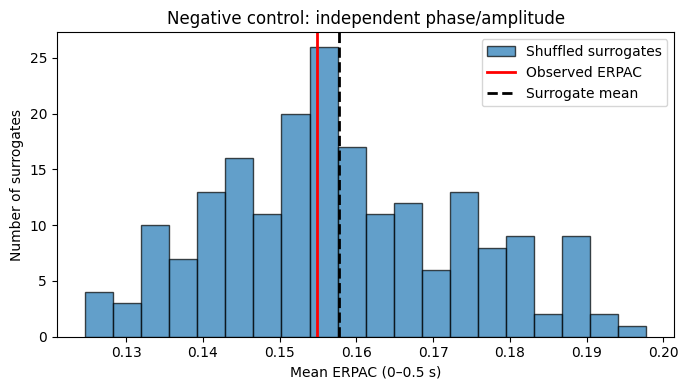

    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
 


--- Positive control: theta-modulated gamma amplitude ---
Observed ERPAC:  0.924674
Surrogate mean:  0.155936
Surrogate SD:    0.044987
Surrogate z:     17.088
Empirical p:     0.0050


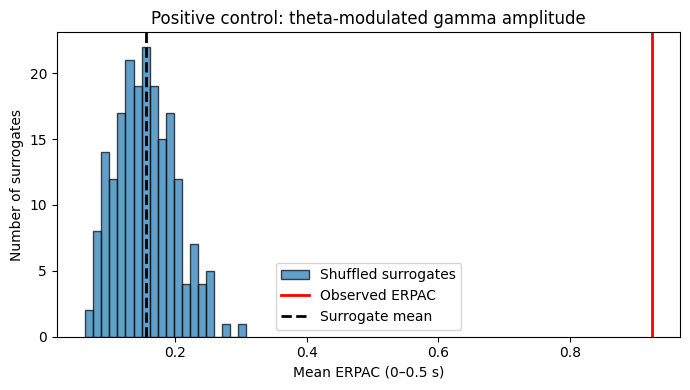

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from tensorpac import EventRelatedPac

# ============================================================
# SETTINGS
# ============================================================

SFREQ = 500
N_TRIALS = 66
N_SURROGATES = 200
SEED = 42

times = np.arange(-0.5, 0.5 + 1 / SFREQ, 1 / SFREQ)
n_times = len(times)

rng = np.random.default_rng(SEED)

# ============================================================
# GENERATE SYNTHETIC THETA PHASE
# ============================================================

# Random phase offset per trial ensures that phase varies
# across trials at each time point.

trial_offsets = rng.uniform(
    -np.pi, np.pi, size=(N_TRIALS, 1)
)

theta_phase = (
    2 * np.pi * 6 * times[np.newaxis, :]
    + trial_offsets
)

# Shape: (1, trials, times)
# Wrap phase values to [-pi, pi]
theta_phase = (theta_phase + np.pi) % (2 * np.pi) - np.pi

# Shape: (1, trials, times)
pha = theta_phase[np.newaxis, :, :]

# ============================================================
# GENERATE GAMMA AMPLITUDE
# ============================================================

# Smooth independent noise
noise = rng.standard_normal((N_TRIALS, n_times))
noise = gaussian_filter1d(noise, sigma=4, axis=-1)

# Standardise noise
noise /= noise.std()

# Negative control:
# Gamma amplitude is independent of theta phase.
amp_uncoupled = np.maximum(
    1.0 + 0.2 * noise, 0.01
)

# Positive control:
# Gamma amplitude depends on theta phase.
amp_coupled = np.maximum(
    1.0
    + 0.7 * np.cos(theta_phase - 0.4)
    + 0.2 * noise,
    0.01
)

# Add frequency dimension
amp_uncoupled = amp_uncoupled[np.newaxis, :, :]
amp_coupled = amp_coupled[np.newaxis, :, :]

# ============================================================
# ERPAC ESTIMATOR
# ============================================================

p = EventRelatedPac(
    f_pha=[4, 8],
    f_amp=[40, 60],
)

def test_erpac(pha, amp, label, seed):

    rng_local = np.random.default_rng(seed)

    observed = np.asarray(
        p.fit(
            pha, amp,
            method="circular",
            n_jobs=1
        )
    ).squeeze()

    surrogate_values = []

    # Analysis window: 0–0.5 s
    mask = (times >= 0) & (times < 0.5)

    observed_mean = observed[mask].mean()

    for _ in range(N_SURROGATES):

        # Shuffle complete amplitude trial time courses
        perm = rng_local.permutation(N_TRIALS)

        shuffled_amp = amp[:, perm, :]

        surrogate = np.asarray(
            p.fit(
                pha,
                shuffled_amp,
                method="circular",
                n_jobs=1
            )
        ).squeeze()

        surrogate_values.append(
            surrogate[mask].mean()
        )

    surrogate_values = np.asarray(surrogate_values)

    null_mean = surrogate_values.mean()
    null_sd = surrogate_values.std(ddof=1)

    z_score = (
        (observed_mean - null_mean) / null_sd
    )

    p_upper = (
        1 + np.sum(surrogate_values >= observed_mean)
    ) / (N_SURROGATES + 1)

    print(f"\n--- {label} ---")
    print(f"Observed ERPAC:  {observed_mean:.6f}")
    print(f"Surrogate mean:  {null_mean:.6f}")
    print(f"Surrogate SD:    {null_sd:.6f}")
    print(f"Surrogate z:     {z_score:.3f}")
    print(f"Empirical p:     {p_upper:.4f}")

    # Visualise the surrogate distribution
    fig, ax = plt.subplots(figsize=(7, 4))

    ax.hist(
        surrogate_values,
        bins=20,
        alpha=0.7,
        edgecolor="black",
        label="Shuffled surrogates"
    )

    ax.axvline(
        observed_mean,
        color="red",
        linewidth=2,
        label="Observed ERPAC"
    )

    ax.axvline(
        null_mean,
        color="black",
        linestyle="--",
        linewidth=2,
        label="Surrogate mean"
    )

    ax.set(
        xlabel="Mean ERPAC (0–0.5 s)",
        ylabel="Number of surrogates",
        title=label
    )

    ax.legend()
    plt.tight_layout()
    plt.show()

    return {
        "observed": observed_mean,
        "surrogate_mean": null_mean,
        "surrogate_sd": null_sd,
        "z": z_score,
        "p": p_upper,
    }


# ============================================================
# RUN NEGATIVE AND POSITIVE CONTROLS
# ============================================================

negative = test_erpac(
    pha,
    amp_uncoupled,
    "Negative control: independent phase/amplitude",
    seed=1
)

positive = test_erpac(
    pha,
    amp_coupled,
    "Positive control: theta-modulated gamma amplitude",
    seed=2
)


Full ERPAC pipeline validation

Event Related PAC object defined
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Com


--- NEGATIVE CONTROL - Independent theta/gamma ---
Observed ERPAC: 0.140154
Surrogate mean: 0.156333
Surrogate SD:   0.012468
Surrogate z:    -1.298
Empirical p:    0.9154


    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
    Correct p-values for multiple-comparisons using fdr correction of MNE-Python
    Compute ERPAC (Voytek et al. 2013)
 


--- POSITIVE CONTROL - Theta-modulated gamma ---
Observed ERPAC: 0.489927
Surrogate mean: 0.155976
Surrogate SD:   0.019483
Surrogate z:    17.141
Empirical p:    0.0050


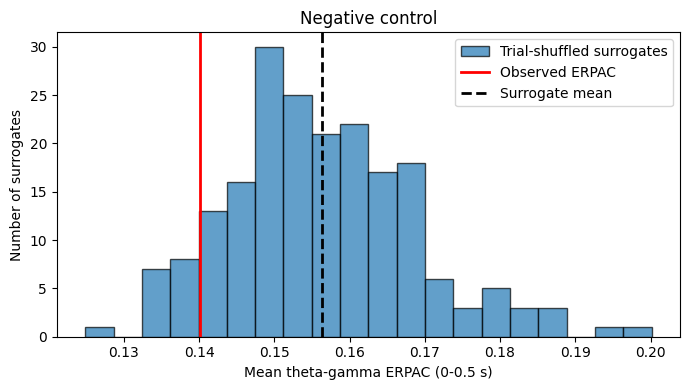

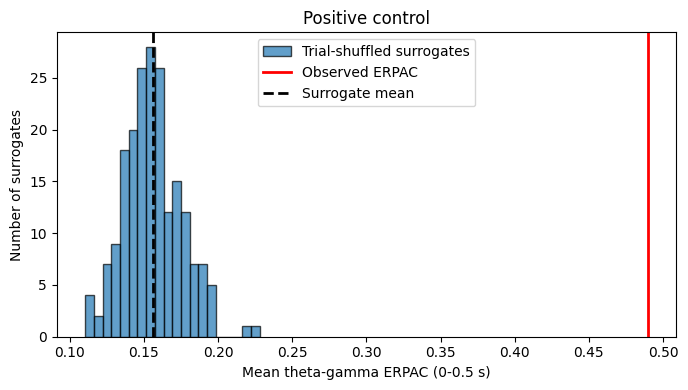

In [5]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from tensorpac import EventRelatedPac

# ============================================================
# 1. SETTINGS
# ============================================================

SFREQ = 500
N_TRIALS = 66
N_SURROGATES = 200
SEED = 42

THETA_FREQ = 6
GAMMA_FREQ = 45

rng = np.random.default_rng(SEED)

# Longer epochs to minimise filtering edge effects
times = np.arange(-1.5, 1.5, 1 / SFREQ)

# Analysis window matching FTT planning
mask = (times >= 0.0) & (times < 0.5)

n_times = len(times)

# ============================================================
# 2. GENERATE SYNTHETIC RAW SIGNALS
# ============================================================

# Random theta phase offset for each trial
theta_offsets = rng.uniform(
    -np.pi, np.pi, (N_TRIALS, 1)
)

theta_phase = (
    2 * np.pi * THETA_FREQ * times[None, :]
    + theta_offsets
)

theta = np.sin(theta_phase)

# Gamma oscillations with random trial-specific phase
gamma_offsets = rng.uniform(
    -np.pi, np.pi, (N_TRIALS, 1)
)

gamma_carrier = np.sin(
    2 * np.pi * GAMMA_FREQ * times[None, :]
    + gamma_offsets
)

# Independent smooth amplitude fluctuations
amp_noise = rng.standard_normal(
    (N_TRIALS, n_times)
)

amp_noise = gaussian_filter1d(
    amp_noise, sigma=12, axis=-1
)

amp_noise /= amp_noise.std()

# Background broadband noise
background = rng.standard_normal(
    (N_TRIALS, n_times)
)

# ------------------------------------------------------------
# NEGATIVE CONTROL
# Theta and gamma amplitude are independent
# ------------------------------------------------------------

envelope_uncoupled = np.maximum(
    1.0 + 0.15 * amp_noise,
    0.05
)

signal_uncoupled = (
    theta
    + 0.5 * envelope_uncoupled * gamma_carrier
    + 0.15 * background
)

# ------------------------------------------------------------
# POSITIVE CONTROL
# Gamma amplitude depends on theta phase
# ------------------------------------------------------------

envelope_coupled = np.maximum(
    1.0
    + 0.8 * np.cos(theta_phase - 0.4)
    + 0.15 * amp_noise,
    0.05
)

signal_coupled = (
    theta
    + 0.5 * envelope_coupled * gamma_carrier
    + 0.15 * background
)

# ============================================================
# 3. ERPAC AND SURROGATE FUNCTION
# ============================================================

def validate_full_erpac(signal, label, seed):

    local_rng = np.random.default_rng(seed)

    # Same frequency settings as Study 2
    p = EventRelatedPac(
        f_pha=[4, 8],
        f_amp=(30, 80, 5, 1),
    )

    # Filter the full 3-second epochs
    pha = p.filter(
        SFREQ, signal,
        ftype="phase",
        n_jobs=1
    )

    amp = p.filter(
        SFREQ, signal,
        ftype="amplitude",
        n_jobs=1
    )

    # Circular ERPAC across trials
    observed = np.asarray(
        p.fit(
            pha, amp,
            method="circular",
            n_jobs=1
        )
    ).squeeze()

    # Average across gamma frequencies and analysis window
    observed_mean = observed[:, mask].mean()

    # --------------------------------------------------------
    # TRIAL-SHUFFLED SURROGATES
    # --------------------------------------------------------

    surrogate_values = []

    for i in range(N_SURROGATES):

        perm = local_rng.permutation(N_TRIALS)

        surrogate = np.asarray(
            p.fit(
                pha,
                amp[:, perm, :],
                method="circular",
                n_jobs=1
            )
        ).squeeze()

        surrogate_values.append(
            surrogate[:, mask].mean()
        )

    surrogate_values = np.asarray(surrogate_values)

    null_mean = surrogate_values.mean()
    null_sd = surrogate_values.std(ddof=1)

    z_score = (
        observed_mean - null_mean
    ) / null_sd

    p_upper = (
        1 + np.sum(surrogate_values >= observed_mean)
    ) / (N_SURROGATES + 1)

    print(f"\n--- {label} ---")
    print(f"Observed ERPAC: {observed_mean:.6f}")
    print(f"Surrogate mean: {null_mean:.6f}")
    print(f"Surrogate SD:   {null_sd:.6f}")
    print(f"Surrogate z:    {z_score:.3f}")
    print(f"Empirical p:    {p_upper:.4f}")

    return {
        "observed": observed,
        "observed_mean": observed_mean,
        "surrogates": surrogate_values,
        "null_mean": null_mean,
        "z": z_score,
        "p": p_upper
    }


# ============================================================
# 4. RUN CONTROLS
# ============================================================

negative = validate_full_erpac(
    signal_uncoupled,
    "NEGATIVE CONTROL - Independent theta/gamma",
    seed=1
)

positive = validate_full_erpac(
    signal_coupled,
    "POSITIVE CONTROL - Theta-modulated gamma",
    seed=2
)

# ============================================================
# 5. VISUALISE SURROGATE DISTRIBUTIONS
# ============================================================

for label, result in [
    ("Negative control", negative),
    ("Positive control", positive)
]:

    fig, ax = plt.subplots(figsize=(7, 4))

    ax.hist(
        result["surrogates"],
        bins=20,
        alpha=0.7,
        edgecolor="black",
        label="Trial-shuffled surrogates"
    )

    ax.axvline(
        result["observed_mean"],
        color="red",
        linewidth=2,
        label="Observed ERPAC"
    )

    ax.axvline(
        result["null_mean"],
        color="black",
        linestyle="--",
        linewidth=2,
        label="Surrogate mean"
    )

    ax.set(
        xlabel="Mean theta-gamma ERPAC (0-0.5 s)",
        ylabel="Number of surrogates",
        title=label
    )

    ax.legend()
    plt.tight_layout()
    plt.show()
